Removed Zero Std Features: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'PSH Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Removed Highly Correlated Features (keeping first occurrence): {'Avg Fwd Segment Size', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'Subflow Fwd Bytes', 'RST Flag Count', 'Fwd Header Length.1', 'Subflow Fwd Packets'}
Elapsed time for TR: 42.1221 seconds
Elapsed time for TS: 4.9897 seconds
0


C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


1
2


C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


3
4


C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


... (46,803 outputs left out)

C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


79997
79998


C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


79999


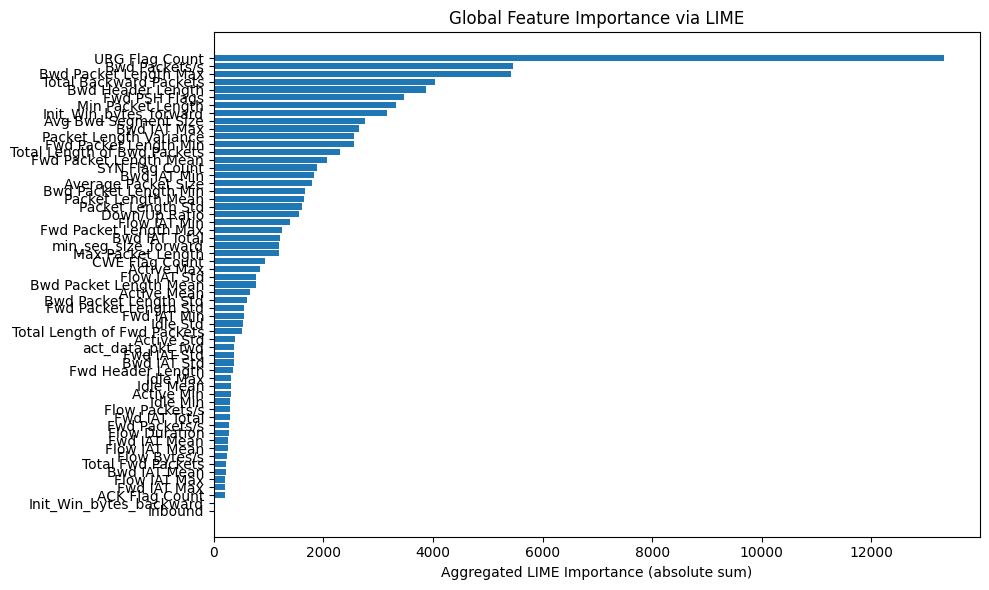

Selected 21 features with importance >= mean (1489.0780):
['URG Flag Count', 'Bwd Packets/s', 'Bwd Packet Length Max', 'Total Backward Packets', 'Bwd Header Length', 'Fwd PSH Flags', 'Min Packet Length', 'Init_Win_bytes_forward', 'Avg Bwd Segment Size', 'Bwd IAT Max', 'Packet Length Variance', 'Fwd Packet Length Min', 'Total Length of Bwd Packets', 'Fwd Packet Length Mean', 'SYN Flag Count', 'Bwd IAT Min', 'Average Packet Size', 'Bwd Packet Length Min', 'Packet Length Mean', 'Packet Length Std', 'Down/Up Ratio']


NameError: name 'top_k' is not defined

In [1]:
# ======================= LIME Feature Selection Pipeline =======================

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from lime.lime_tabular import LimeTabularExplainer
from collections import defaultdict
import matplotlib.pyplot as plt
%matplotlib inline
import time

# 1. Load and prepare dataset
# Replace with your data if needed
# Example: df = pd.read_csv("your_data.csv")
def CORRELATED(df1):
    X=df1.drop('Label', axis=1)
    original_columns = set(X.columns)
    
    ### 1. Remove features with zero standard deviation ###
    zero_std_features = [col for col in X.columns if X[col].std() == 0]
    X = X.drop(columns=zero_std_features)
    print("Removed Zero Std Features:", zero_std_features)
    
    ### 2. Remove highly correlated features (keep first occurrence) ###
    correlation_matrix = X.corr().abs()
    upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    
    # Identify highly correlated feature pairs (keep first occurrence)
    highly_correlated_features = set()
    for column in upper_triangle.columns:
        correlated_cols = upper_triangle.index[upper_triangle[column] == 1].tolist()
        for col in correlated_cols:
            if col not in highly_correlated_features:  # Keep the first occurrence
                highly_correlated_features.add(column)
    
    X = X.drop(columns=highly_correlated_features)
    print("Removed Highly Correlated Features (keeping first occurrence):", highly_correlated_features)
    
    ### 3. Remove redundant features (identical columns) ###
    # duplicate_features = X.T.duplicated()
    # redundant_features = X.columns[duplicate_features].tolist()
    # X = X.loc[:, ~duplicate_features]
    # print("Removed Redundant Features:", redundant_features)
    X['Label']=df1['Label']
    return X
file_path = r"D:\Datasets\Dataset_4L\CICDDoS2019_87F_TRAIN_DATASET_FRONT_SEQUANTIAL_BINARY_CLASS_4L.csv"
df = pd.read_csv(file_path, low_memory=False)

df.drop(columns=['Flow ID','Source IP','Source Port','Destination IP','Destination Port','Protocol','Timestamp','SimillarHTTP'],inplace=True)

df = CORRELATED(df)
X = df.drop(columns=["Label"])  # Replace 'Label' with your label column if different
y = df["Label"]

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
start = time.time()
# 3. Train RandomForest model
model = RandomForestClassifier()
model.fit(X_train, y_train)
end = time.time()

elapsed = end - start
print(f"Elapsed time for TR: {elapsed:.4f} seconds")

start = time.time()
# 4. Initialize LIME Explainer
explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X.columns.tolist(),
    class_names=np.unique(y_train).astype(str),
    mode='classification'
)
end = time.time()

elapsed = end - start
print(f"Elapsed time for TS: {elapsed:.4f} seconds")

# 5. Aggregate LIME feature importance across samples
valid_features = list(X.columns)
feature_scores = defaultdict(float)
num_samples = len(X_test)  # Or reduce for speed

for i in range(num_samples):
    exp = explainer.explain_instance(
        X_test.iloc[i].values,
        model.predict_proba,
        num_features=len(X.columns)
    )
    print(i)
    for feature_desc, weight in exp.as_list():
        # Find matching real column name from LIME output string
        for col in valid_features:
            if col in feature_desc:
                feature_scores[col] += abs(weight)
                break
importance_df = pd.DataFrame(list(feature_scores.items()), columns=["Feature", "LIME Importance"])
importance_df.sort_values(by="LIME Importance", ascending=False, inplace=True)
importance_df.reset_index(drop=True, inplace=True)

# 7. Plot global feature importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["LIME Importance"])
plt.xlabel("Aggregated LIME Importance (absolute sum)")
plt.title("Global Feature Importance via LIME")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 8. Select top-k features
mean_importance = importance_df["LIME Importance"].mean()

# Select features with importance >= mean
selected_features = importance_df[importance_df["LIME Importance"] >= mean_importance]["Feature"].tolist()

print(f"Selected {len(selected_features)} features with importance >= mean ({mean_importance:.4f}):")
print(selected_features)

# 9. Filter dataset to selected features and retrain
X_selected = X[selected_features]
X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
    X_selected, y, test_size=0.2, random_state=42)

model_sel = RandomForestClassifier()
model_sel.fit(X_train_sel, y_train_sel)

accuracy = model_sel.score(X_test_sel, y_test_sel)
print(f"Model accuracy with top-{len(selected_features)} LIME-selected features: {accuracy:.4f}")

In [3]:
importance_df

,Feature,LIME Importance
0,URG Flag Count,13315.849723
1,Bwd Packets/s,5457.564000
2,Bwd Packet Length Max,5428.349551
3,Total Backward Packets,4038.514140
4,Bwd Header Length,3868.025799
5,Fwd PSH Flags,3475.027032
6,Min Packet Length,3323.951138
7,Init_Win_bytes_forward,3155.469039
8,Avg Bwd Segment Size,2753.480380
9,Bwd IAT Max,2644.368886


In [4]:
importance_df.to_csv("LIME_feature_importance_with_80K.csv", index=False)